# **PROYECTO IA - MODELO PREDICTIVO DE ICTUS** 🧠
## 👥 Grupo 5: Víctor Chinchilla, Laia García, Cristina Masiá
---

## 0. Carga de librerías

In [123]:
# --- LIBRERÍAS ---

# Operaciones numéricas y manejo de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# --- PREPROCESAMIENTO ---

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- SELECCIÓN Y VALIDACIÓN DE MODELOS ---

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, cross_val_predict, train_test_split

# --- MÉTRICAS ---

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score
)

# --- BALANCEO DE CLASES ---

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# --- MODELOS ---

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# --- INTERPRETABILIDAD ---

from sklearn.inspection import permutation_importance

# --- CONFIGURACIÓN ---

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

print("✅ Librerías cargadas")

✅ Librerías cargadas


## 1. Preparación dataset

In [2]:
df = pd.read_csv('stroke_enriquecido.csv', na_values=['N/A'])
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,...,age_group,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,...,senior,1,0.0,67.0,153.22,1,0,1,1,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,...,senior,0,0.0,0.0,123.35,1,0,1,0,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,...,senior,1,0.0,80.0,84.74,1,0,0,1,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,...,adulto,0,0.0,0.0,83.90,0,0,1,1,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,...,senior,1,79.0,0.0,137.55,1,0,1,0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  5110 non-null   int64  
 1   gender              5110 non-null   object 
 2   age                 5110 non-null   float64
 3   hypertension        5110 non-null   int64  
 4   heart_disease       5110 non-null   int64  
 5   ever_married        5110 non-null   object 
 6   work_type           5110 non-null   object 
 7   Residence_type      5110 non-null   object 
 8   avg_glucose_level   5110 non-null   float64
 9   bmi                 4909 non-null   float64
 10  smoking_status      5110 non-null   object 
 11  bmi_missing         5110 non-null   int64  
 12  glucose_category    5110 non-null   object 
 13  bmi_category        5110 non-null   object 
 14  age_group           5110 non-null   object 
 15  comorbidity_count   5110 non-null   int64  
 16  age_x_

In [4]:
df.describe().round(3)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,bmi_missing,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,stroke
count,5110.000,5110.000,5110.000,5110.000,5110.000,4909.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000
mean,36517.829,43.227,0.097,0.054,106.148,28.893,0.039,0.151,6.066,3.683,48.322,0.269,0.168,0.192,0.376,0.049
std,21161.722,22.613,0.297,0.226,45.284,7.854,0.194,0.392,18.976,15.649,38.836,0.444,0.373,0.394,0.484,0.215
min,67.000,0.080,0.000,0.000,55.120,10.300,0.000,0.000,0.000,0.000,0.060,0.000,0.000,0.000,0.000,0.000
25%,17741.250,25.000,0.000,0.000,77.245,23.500,0.000,0.000,0.000,0.000,21.792,0.000,0.000,0.000,0.000,0.000
50%,36932.000,45.000,0.000,0.000,91.885,28.100,0.000,0.000,0.000,0.000,39.595,0.000,0.000,0.000,0.000,0.000
75%,54682.000,61.000,0.000,0.000,114.090,33.100,0.000,0.000,0.000,0.000,60.798,1.000,0.000,0.000,1.000,0.000
max,72940.000,82.000,1.000,1.000,271.740,97.600,1.000,2.000,82.000,82.000,207.700,1.000,1.000,1.000,1.000,1.000


In [5]:
df.shape

(5110, 24)

In [6]:
# Valores nulos
is_null = df.isna().any()
print("Columnas con NULOS:")
print(df.isna().sum()[df.isna().sum() > 0])

Columnas con NULOS:
bmi    201
dtype: int64


In [7]:
# Valores infinitos
is_inf = df.isin([np.inf, -np.inf]).any()
print("Columnas con INFINITOS:")
print(is_inf[is_inf])

Columnas con INFINITOS:
Series([], dtype: bool)


In [8]:
# Valores duplicados
print("Columnas con DUPLICADOS:")
print(df.duplicated().sum())

Columnas con DUPLICADOS:
0


In [9]:
# Revisar categorías para que no haya inconsistencias
for col in df.select_dtypes(include="object"):
    print(col)
    print(df[col].unique())
    print()

gender
['Male' 'Female']

ever_married
['Yes' 'No']

work_type
['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Residence_type
['Urban' 'Rural']

smoking_status
['formerly smoked' 'never smoked' 'smokes' 'Unknown']

glucose_category
['diabetes' 'prediabetes' 'normal']

bmi_category
['obesidad' 'desconocido' 'normal' 'sobrepeso' 'bajo_peso']

age_group
['senior' 'adulto' 'adulto_joven' 'menor']



In [10]:
# Valores target (stroke)
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [11]:
# Eliminar columna "id" ya que no aporta información relevante
df = df.drop(columns="id")

In [12]:
# Comprobación de que la columna "id" se ha eliminado correctamente
print("Columnas:\n", df.columns)
print("\nShape:", df.shape)

Columnas:
 Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'bmi_missing', 'glucose_category', 'bmi_category',
       'age_group', 'comorbidity_count', 'age_x_hypertension', 'age_x_heart',
       'age_x_glucose', 'is_elderly', 'is_child', 'glucose_high', 'obese',
       'stroke'],
      dtype='object')

Shape: (5110, 23)


## 2. Análisis exploratorio de los datos (EDA)

### Porcentaje de pacientes con ictus

In [13]:
(df["stroke"].value_counts(normalize=True) * 100).round(3)

stroke
0    95.127
1     4.873
Name: proportion, dtype: float64

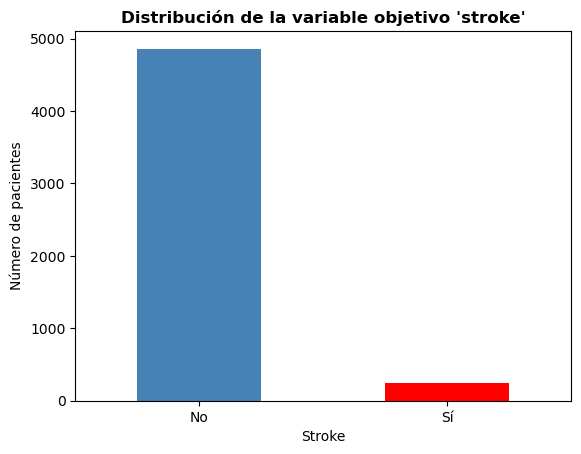

In [14]:
# Visualización del porcentaje
df["stroke"].value_counts().plot(kind="bar", color=["steelblue", "red"])

plt.title("Distribución de la variable objetivo 'stroke'", fontweight = "bold")
plt.xlabel("Stroke")
plt.ylabel("Número de pacientes")
plt.xticks([0,1],["No","Sí"], rotation=0)
plt.show()

In [15]:
# Cálculo de la accuracy si predecimos siempre "No hay ictus"
accuracy_no_ictus = (df["stroke"] == 0).mean()
print(f"Accuracy si un modelo siempre predijera 'No hay ictus': {accuracy_no_ictus:.2%}")

Accuracy si un modelo siempre predijera 'No hay ictus': 95.13%


In [16]:
# Predicción trivial: siempre "No hay ictus"
y_true = df["stroke"]
y_pred = [0] * len(df)

recall = recall_score(y_true, y_pred)
print(f"Recall si un modelo siempre predijera 'No hay ictus': {recall:.2f}")

Recall si un modelo siempre predijera 'No hay ictus': 0.00


> Un modelo que siempre predijera "No hay ictus" tendría un **95%** de **_accuracy_**, pero no detectaría nunca ningún ictus (`recall = 0`). Por ello, la accuracy no será una métrica adecuada y se priorizarán métricas como **Recall, F1-Score y ROC-AUC**.

### Valores faltantes en BMI

In [17]:
(df.groupby(df["bmi"].isna())["stroke"].mean() * 100).round(3)

bmi
False     4.257
True     19.900
Name: stroke, dtype: float64

> Observamos que los pacientes con **BMI conocido** presentan una tasa de ictus del **4%**, mientras que los pacientes con **BMI desconocido** presentan una tasa del **20%**. Esto indica que los pacientes del segundo grupo tienen una probabilidad casi **5 veces mayor**.
>
> Es por ello por lo que no podemos obviar esa información y sería conveniente rellenar esos datos con la mediana (es más robusta que la media).

### Fuerza variables categóricas

In [18]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(((df.groupby(col)["stroke"].mean().sort_values(ascending=False)) * 100).round(3), "\n")

gender
Male      5.106
Female    4.708
Name: stroke, dtype: float64 

ever_married
Yes    6.561
No     1.651
Name: stroke, dtype: float64 

work_type
Self-employed    7.937
Private          5.094
Govt_job         5.023
children         0.291
Never_worked     0.000
Name: stroke, dtype: float64 

Residence_type
Urban    5.200
Rural    4.535
Name: stroke, dtype: float64 

smoking_status
formerly smoked    7.910
smokes             5.323
never smoked       4.757
Unknown            3.044
Name: stroke, dtype: float64 

glucose_category
diabetes       10.194
prediabetes     3.707
normal          3.577
Name: stroke, dtype: float64 

bmi_category
desconocido    19.900
sobrepeso       5.323
obesidad        5.104
normal          2.816
bajo_peso       0.297
Name: stroke, dtype: float64 

age_group
senior          13.154
adulto           3.836
adulto_joven     0.457
menor            0.234
Name: stroke, dtype: float64 



> Las variables que muestran diferencias grandes son **ever_married, work_type y smoking_status**.

### Fuerza variables numéricas

In [19]:
numeric_columns = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_columns:
    print(((df.groupby(col)["stroke"].mean().sort_values(ascending=False)) * 100).round(3), "\n")

age
80.0    24.286
81.0    23.333
74.0    22.500
78.0    20.588
79.0    20.000
         ...  
11.0     0.000
10.0     0.000
9.0      0.000
8.0      0.000
31.0     0.000
Name: stroke, Length: 104, dtype: float64 

hypertension
1    13.253
0     3.968
Name: stroke, dtype: float64 

heart_disease
1    17.029
0     4.179
Name: stroke, dtype: float64 

avg_glucose_level
271.74    100.0
174.12    100.0
194.37    100.0
194.99    100.0
195.23    100.0
          ...  
83.89       0.0
83.91       0.0
83.93       0.0
83.94       0.0
95.19       0.0
Name: stroke, Length: 3979, dtype: float64 

bmi
44.1    100.0
36.5     75.0
42.5     50.0
45.7     50.0
56.6     50.0
        ...  
27.6      0.0
26.0      0.0
25.9      0.0
25.7      0.0
97.6      0.0
Name: stroke, Length: 418, dtype: float64 

bmi_missing
1    19.900
0     4.257
Name: stroke, dtype: float64 

comorbidity_count
2    20.312
1    13.467
0     3.386
Name: stroke, dtype: float64 

age_x_hypertension
68.0    40.000
80.0    33.333
74.0    

### Menores con ictus

In [20]:
# Calcular número de menores en el dataset
menores = df[df["age"] < 18]

print(f"Número de menores: {len(menores)}")
print(f"Porcentaje: {len(menores)/len(df)*100:.2f}%")

Número de menores: 856
Porcentaje: 16.75%


In [21]:
# Menores con ictus
menores["stroke"].value_counts()

print("Tasa de ictus en menores:", (menores["stroke"].mean()*100).round(2))

Tasa de ictus en menores: 0.23


In [22]:
# Influencia de otras variables sobre los menores
variables = [
    "work_type",
    "smoking_status",
    "ever_married",
    "gender",
    "Residence_type"
]

for variable in variables:

    print(f"\n{'='*50}")
    print(variable)

    tabla = pd.crosstab(
        df["age"] < 18,
        df[variable],
        normalize="index"
    ) * 100

    print(tabla.round(2))


work_type
work_type  Govt_job  Never_worked  Private  Self-employed  children
age                                                                
False          15.3          0.12    65.61          18.97      0.00
True            0.7          1.99    15.65           1.40     80.26

smoking_status
smoking_status  Unknown  formerly smoked  never smoked  smokes
age                                                           
False             20.26            20.22         41.18   18.34
True              79.67             2.92         16.36    1.05

ever_married
ever_married      No    Yes
age                        
False          21.18  78.82
True          100.00   0.00

gender
gender  Female   Male
age                  
False    60.58  39.42
True     48.83  51.17

Residence_type
Residence_type  Rural  Urban
age                         
False           49.01  50.99
True            50.12  49.88


> Las variables que más influyen sobre los menores son **work_type, smoking_status y ever_married** ya que eran las que mostraban más diferencias y están más influidas por la edad, el cual es uno de los principales factores de riesgo de ictus.

### Niveles de glucosa

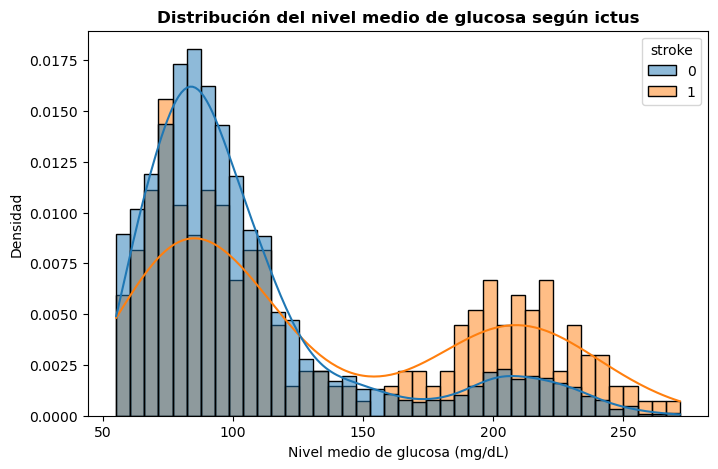

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="avg_glucose_level",
    hue="stroke",
    bins=40,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Distribución del nivel medio de glucosa según ictus", fontweight = "bold")
plt.xlabel("Nivel medio de glucosa (mg/dL)")
plt.ylabel("Densidad")
plt.show()

> La distribución es **asimétrica** hacia la derecha (muestra una cola en valores elevados de glucosa) y puede sugerir la presencia de **más de una subpoblación**. Desde un punto de vista clínico podrían ser pacientes con **niveles de glucosa normales** (70 - 120 mg/dL) y pacientes con **hiperglucemia o diabetes** (150 - 250 mg/dL.)

### Matriz de confusión

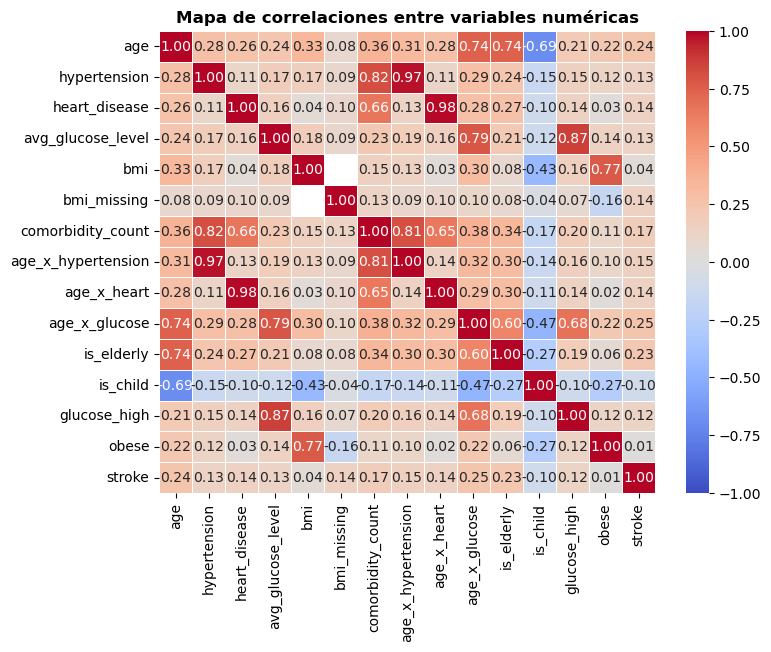

In [24]:
# Correlación variables numéricas
corr = df[numeric_columns].corr().round(3)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Mapa de correlaciones entre variables numéricas", fontweight = "bold")
plt.show()

> Los pares con mayor correlación son las variables influenciadas por la **edad**, lo que demuestra que este es el factor de mayor riesgo ante un posible ictus. Cuanta más edad tenga el paciente, mayor probabilidad de padecer un ictus. Eso unido a factores como **la hipertensión, la enfermedad cardíaca, los niveles de glucosa y el BMI**, hacen que aumente dicha probabilidad.
>
> `bmi` y `bmi_missing` no muestran el tipo de correlación porque hay valores faltantes (NaN) en `bmi`.

## 3. Validación del modelo

In [25]:
# Variables predictoras (X) y variable objetivo (y)
X = df.drop(columns="stroke")
y = df["stroke"]

In [26]:
# 80 % train - 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,   # Estratificación para evitar desproporción de casos de ictus
    random_state=42
)

# Validación cruzada con StratifiedKFold que evita folds con pocos positivos
validacion_cruzada = StratifiedKFold(
    n_splits=5,   # 4/5 train + 1/5 validation
    shuffle=True,
    random_state=42
)

In [27]:
# Comprobación del reparto de pacientes durante el entrenamiento y prueba
print(f"Train: {X_train.shape[0]} pacientes")
print(f"Test: {X_test.shape[0]} pacientes")
print("\nDistribución de stroke en train (%):")
print((y_train.value_counts(normalize=True) * 100).round(3))

# Comprobación de que cada fold de validación conserva ambas clases
print()
for fold, (_, idx_validacion) in enumerate(validacion_cruzada.split(X_train, y_train), start=1):
    positivos_fold = y_train.iloc[idx_validacion].sum()
    print(f"Fold {fold}: {positivos_fold} positivos de {len(idx_validacion)} pacientes")

Train: 4088 pacientes
Test: 1022 pacientes

Distribución de stroke en train (%):
stroke
0    95.132
1     4.868
Name: proportion, dtype: float64

Fold 1: 40 positivos de 818 pacientes
Fold 2: 40 positivos de 818 pacientes
Fold 3: 40 positivos de 818 pacientes
Fold 4: 39 positivos de 817 pacientes
Fold 5: 40 positivos de 817 pacientes


> Comprobamos que el reparto de pacientes se ha hecho correctamente (**80/20**) y que la distribución de pacientes con ictus se sigue respetando (**4,87%**). Del mismo modo, comprobamos de forma desglosada dicho reparto y distribución a lo largo de los 5 folds.
>
> Por otra parte, elegimos **5 folds** para que en cada iteración se entrene el 80% y se valide el 20% restante. Si eligiéramos más o menos folds aumentaríamos o disminuiríamos el sesgo, respectivamente haciendo que no pudiéramos calcular correctamente las métricas.

## 4. Preprocesamiento

In [28]:
# Identificar las columnas numéricas y categóricas del X_train
col_num = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
col_cat = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Columnas numéricas:\n", col_num)
print("\nColumnas categóricas:\n", col_cat)

# --- VARIABLES NUMÉRICAS ---
transformador_num = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),   # Usamos la mediana para los NaN porque es más robusta que, por ejemplo, la media
    ("escalado", StandardScaler())   # Lo usamos inicialmente para regresión logística y SVM
])

# Versión para modelos SIN escalado
transformador_num_sin_escalado = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median"))
])

# --- VARIABLES CATEGÓRICAS ---
transformador_cat = Pipeline(steps=[ 
    ("imputacion", SimpleImputer(
        strategy="constant",
        fill_value="Missing"   # Un NaN real se convierte en una categoría distinta
    )),
    ("codificacion", OneHotEncoder(
        handle_unknown="infrequent_if_exist",   # Evita errores si apareciera una categoría que no estaba en el entrenamiento
        drop="if_binary",   # Elimina una de las columnas en las variables binarias como `gender` o `Residence_type`
        min_frequency=0.01   # Las variables de > 1% se agrupan como infrecuentes
    ))
])

# --- ESCALADO ---
# CON escalado (Logistic Regression y SVM)
preprocessor_con_escalado = ColumnTransformer(transformers=[
    ("numericas", transformador_num, col_num),
    ("categoricas", transformador_cat, col_cat)
])

# SIN escalado (Random Forest, XGBoost y GaussianNB)
preprocessor_sin_escalado = ColumnTransformer(transformers=[
    ("numericas", transformador_num_sin_escalado, col_num),
    ("categoricas", transformador_cat, col_cat)
])

print("\n✅ Preprocesamiento realizado con éxito")

Columnas numéricas:
 ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'bmi_missing', 'comorbidity_count', 'age_x_hypertension', 'age_x_heart', 'age_x_glucose', 'is_elderly', 'is_child', 'glucose_high', 'obese']

Columnas categóricas:
 ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status', 'glucose_category', 'bmi_category', 'age_group']

✅ Preprocesamiento realizado con éxito


> Durante el preprocesamiento hemos **separado las variables numéricas de las categóricas** y les hemos aplicado la imputación, el escalado y la codificación cuando ha correspondido. A partir de ahí podemos crear el **preprocesamiento con y sin escalado**.

## 5. Balanceo de clases

In [29]:
# Métricas para comparar las estrategias (sin accuracy porque al haber 4,87% de ictus podría falsear los resultados)
metricas = {
    "Recall": "recall",
    "Precision": "precision",
    "F1-Score": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision"
}

# --- COMPARACIÓN DE ESTRATEGIAS ---
estrategias_balanceo = {
    "Sin compensación": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("modelo", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))]),
    "Pesos balanceados": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))]),
    "RandomOverSampler": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("balanceo", RandomOverSampler(random_state=42)),
        ("modelo", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))])
}

# --- VALIDACIÓN CRUZADA ---
resultados_balanceo = []

for nombre, pipeline in estrategias_balanceo.items():
    resultados_cv = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=validacion_cruzada,
        scoring=metricas,
        return_train_score=False
    )
    fila = {"Estrategia": nombre}
    for metrica in metricas:
        fila[f"{metrica} media"] = resultados_cv[f"test_{metrica}"].mean()
        fila[f"{metrica} std"] = resultados_cv[f"test_{metrica}"].std()
    resultados_balanceo.append(fila)

# --- TABLA COMPARATIVA ---
tabla_balanceo = pd.DataFrame(resultados_balanceo)
tabla_balanceo.round(3)

,Estrategia,Recall media,Recall std,Precision media,Precision std,F1-Score media,F1-Score std,ROC-AUC media,ROC-AUC std,PR-AUC media,PR-AUC std
0,Sin compensación,0.010,0.012,0.267,0.389,0.019,0.023,0.854,0.012,0.229,0.041
1,Pesos balanceados,0.784,0.043,0.135,0.010,0.230,0.016,0.851,0.013,0.225,0.038
2,RandomOverSampler,0.789,0.038,0.137,0.010,0.234,0.016,0.849,0.014,0.230,0.047


> Hemos realizado una comparación de las **3 estrategias (sin compensación, pesos balanceados y remuestreo)** y hemos podido observar que el **Recall** aumenta significativamente al aplicar los pesos balanceados o el remuestreo, pero que no hay diferencias notables entre una estrategia y otra. Es por ello por lo que elegimos la estrategia de **pesos balanceados**, ya que es más simple y no requiere que se dupliquen los pacientes con ictus.

## 6. Reducción/selección de variables

In [30]:
# Contamos las variables transformadas
preprocessor_recuento = clone(preprocessor_con_escalado)
X_train_transformado = preprocessor_recuento.fit_transform(X_train)

print("Número de variables transformadas tras el preprocesamiento:", X_train_transformado.shape[1])

Número de variables transformadas tras el preprocesamiento: 38


In [31]:
# Métricas para comparar rendimiento (sin accuracy porque al haber 4,87% de ictus podría falsear los resultados)
metricas = {
    "Recall": "recall",
    "Precision": "precision",
    "F1-Score": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision"
}

# --- COMPARACIÓN MÉTODOS REDUCCIÓN ---
estrategias_reduccion = {
    "Sin reducción": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("modelo", LogisticRegression(
            class_weight="balanced",   # Aplicamos pesos balanceados
            max_iter=1000,
            random_state=42
        ))]),
    "PCA 95% varianza": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("pca", PCA(
            n_components=0.95,   # Número mínimo de componentes que explica el 95% de la variabilidad de los datos
            svd_solver="full"
        )),
        ("modelo", LogisticRegression(
            class_weight="balanced",   # Aplicamos pesos balanceados
            max_iter=1000,
            random_state=42
        ))]),
    "SelectKBest (10)": ImbPipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("seleccion", SelectKBest(
            score_func=mutual_info_classif,
            k=10   # Elegimos las 10 mejores variables
        )),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))]),
    "Logistic Regression L1": ImbPipeline([
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))])
}

# --- VALIDACIÓN CRUZADA ---
resultados_reduccion = []

for nombre, pipeline in estrategias_reduccion.items():
    resultados_cv = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=validacion_cruzada,
        scoring=metricas,
        return_train_score=False
    )
    fila = {"Estrategia": nombre}
    for metrica in metricas:
        fila[f"{metrica} media"] = resultados_cv[f"test_{metrica}"].mean()
        fila[f"{metrica} std"] = resultados_cv[f"test_{metrica}"].std()
    resultados_reduccion.append(fila)

# --- TABLA COMPARATIVA ---
tabla_reduccion = pd.DataFrame(resultados_reduccion)
tabla_reduccion.round(3)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0

,Estrategia,Recall media,Recall std,Precision media,Precision std,F1-Score media,F1-Score std,ROC-AUC media,ROC-AUC std,PR-AUC media,PR-AUC std
0,Sin reducción,0.784,0.043,0.135,0.010,0.230,0.016,0.851,0.013,0.225,0.038
1,PCA 95% varianza,0.799,0.043,0.132,0.009,0.227,0.015,0.850,0.010,0.215,0.034
2,SelectKBest (10),0.814,0.041,0.136,0.012,0.233,0.019,0.846,0.015,0.213,0.051
3,Logistic Regression L1,0.779,0.043,0.134,0.010,0.228,0.016,0.851,0.013,0.226,0.040


> Al observar la tabla vemos que **PCA al 95% de varianza** apenas ha aumentado su Recall respecto al modelo sin reducción. **SelectKBest con 10 variables** sí que consigue aumentar sus valores respecto al resto de estrategias. **Logistic Regression (L1)**, en cambio, se ha mantenido en valores muy similares a los del modelo original. Todo esto nos indica que la mejor estrategia a aplicar es la de **SelectKBest**.

In [120]:
# Probamos otras alternativas como importancia de variables, Logistic Regression o Variance Inflation Factor

# --- IMPORTANCIA DE VARIABLES ---
# Coeficientes Logistic Regression
pipeline_LR = ImbPipeline(steps=[
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))])

pipeline_LR.fit(X_train, y_train)

variables_LR = pipeline_LR.named_steps["preprocesamiento"].get_feature_names_out()
coeficientes_LR = pipeline_LR.named_steps["modelo"].coef_[0]

importancia_LR = (pd.DataFrame({"Variable": variables_LR, "Coeficiente": coeficientes_LR, "Importancia": abs(coeficientes_LR)}).sort_values("Importancia", ascending=False))
print("Coeficientes Logistic Regression:\n")
print(display(importancia_LR.head(20).round(3)))   # Tabla donde se observa si una variable aumenta o disminuye la probabilidad de ictus

# Random Forest (feature_importances_)
pipeline_RF = ImbPipeline([
    ("preprocesamiento", preprocessor_sin_escalado),
    ("modelo", RandomForestClassifier(
        random_state=42
    ))])

pipeline_RF.fit(X_train, y_train)

variables_RF = pipeline_RF.named_steps["preprocesamiento"].get_feature_names_out()
importancias_RF = pipeline_RF.named_steps["modelo"].feature_importances_

tabla_RF = (pd.DataFrame({"Variable": variables_RF, "Importancia": importancias_RF}).sort_values("Importancia", ascending=False))
print("\nRandom Forest:\n")
print(display(tabla_RF.head(20).round(3)))

# --- LOGISTIC REGRESSION (L1/LASSO) ---
pipeline_L1 = ImbPipeline([
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

pipeline_L1.fit(X_train, y_train)

coeficientes_L1 = pipeline_L1.named_steps["modelo"].coef_[0]
variables_L1 = pipeline_L1.named_steps["preprocesamiento"].get_feature_names_out()
seleccionadas_L1 = pd.DataFrame({"Variable": variables_L1, "Coeficiente": coeficientes_L1})

print("\nLogistic Regression L1/Lasso:\n")
print(display(seleccionadas_L1[seleccionadas_L1["Coeficiente"] != 0].round(3)))

# --- VARIANCE INFLATION FACTOR (VIF) ---
X_VIF = X_train[col_num].copy()
imputer = SimpleImputer(strategy="median")

X_VIF = pd.DataFrame(imputer.fit_transform(X_VIF), columns=X_VIF.columns)
VIF = pd.DataFrame()

VIF["Variable"] = X_VIF.columns
VIF["VIF"] = [
    variance_inflation_factor(X_VIF.values, i)
    for i in range(X_VIF.shape[1])
]

VIF = VIF.sort_values("VIF", ascending=False)
print("\nVIF:\n")
VIF.round(3)

Coeficientes Logistic Regression:



,Variable,Coeficiente,Importancia
0,numericas__age,2.239,2.239
19,categoricas__work_type_children,1.227,1.227
8,numericas__age_x_heart,-0.673,0.673
29,categoricas__bmi_category_bajo_peso,-0.672,0.672
18,categoricas__work_type_Self-employed,-0.607,0.607
35,categoricas__age_group_adulto_joven,-0.589,0.589
7,numericas__age_x_hypertension,-0.565,0.565
6,numericas__comorbidity_count,0.526,0.526
16,categoricas__work_type_Govt_job,-0.443,0.443
15,categoricas__ever_married_Yes,-0.440,0.440


None

Random Forest:



,Variable,Importancia
9,numericas__age_x_glucose,0.158
3,numericas__avg_glucose_level,0.146
0,numericas__age,0.128
4,numericas__bmi,0.116
7,numericas__age_x_hypertension,0.036
21,categoricas__Residence_type_Urban,0.026
14,categoricas__gender_Male,0.026
8,numericas__age_x_heart,0.024
24,categoricas__smoking_status_never smoked,0.022
17,categoricas__work_type_Private,0.022


None


...


Logistic Regression L1/Lasso:



,Variable,Coeficiente
0,numericas__age,2.332
2,numericas__heart_disease,0.131
3,numericas__avg_glucose_level,-0.197
4,numericas__bmi,0.023
5,numericas__bmi_missing,0.337
6,numericas__comorbidity_count,0.975
7,numericas__age_x_hypertension,-0.548
8,numericas__age_x_heart,-0.630
9,numericas__age_x_glucose,0.234
10,numericas__is_elderly,-0.431


None

VIF:



/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Variable,VIF
1,hypertension,inf
2,heart_disease,inf
6,comorbidity_count,inf
8,age_x_heart,46.076
3,avg_glucose_level,40.962
9,age_x_glucose,31.740
4,bmi,31.345
0,age,27.985
7,age_x_hypertension,22.518
12,glucose_high,4.398


> Tras aplicar distintas estrategias hemos podido observar en los **coeficientes de Logistic Regression** que la **edad** es la variable que más aumenta la probabilidad de sufrir un ictus. En el caso de **Random Forest** es la **edad** y la **glucosa**. Y, por último, en el caso **VIF**, la variable con mayor multicolinealidad es la **influencia de la edad sobre la enfermedad cardíaca**  (`age_x_heart`).
>
> Todo esto nos muestra que la variable que más influye sobre la probabilidad de padecer ictus es la **edad** y su relación con el metabolismo y la enfermedad cardíaca.

## 7. Selección y comparación de modelos

In [33]:
# Métricas para comparar modelos
metricas = {
    "Recall": "recall",
    "Precision": "precision",
    "F1-Score": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision"
}

# -- SELECCIÓN DE MODELOS ---
modelos = {
    "Dummy": Pipeline(steps=[   # Modelo de referencia
        ("preprocesamiento", preprocessor_sin_escalado),
        ("modelo", DummyClassifier(strategy="most_frequent"))   # Predice la clase mayoritaria (no ictus)
    ]),
    "Logistic Regression": Pipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))]),
    "Naive Bayes": Pipeline(steps=[
        ("preprocesamiento", preprocessor_sin_escalado),
        ("modelo", GaussianNB())
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocesamiento", preprocessor_sin_escalado),
        ("modelo", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42
        ))]),
    "XGBoost": Pipeline(steps=[
        ("preprocesamiento", preprocessor_sin_escalado),
        ("modelo", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),   # Cálculo de la relación positivos/negativos
            random_state=42
        ))]),
    "SVM": Pipeline(steps=[
        ("preprocesamiento", preprocessor_con_escalado),
        ("modelo", SVC(
            class_weight="balanced",
            probability=True,
            random_state=42
        ))])}

# --- VALIDACIÓN CRUZADA ---
resultados_modelos = []

for nombre, pipeline in modelos.items():
    resultados_cv = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=validacion_cruzada,
        scoring=metricas,
        return_train_score=False
    )
    fila = {"Modelo": nombre}
    for metrica in metricas:
        fila[f"{metrica} media"] = resultados_cv[f"test_{metrica}"].mean()
        fila[f"{metrica} std"] = resultados_cv[f"test_{metrica}"].std()
    resultados_modelos.append(fila)

# --- TABLA COMPARATIVA ---
tabla_modelos = pd.DataFrame(resultados_modelos)
tabla_modelos.round(3)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklea

,Modelo,Recall media,Recall std,Precision media,Precision std,F1-Score media,F1-Score std,ROC-AUC media,ROC-AUC std,PR-AUC media,PR-AUC std
0,Dummy,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.049,0.000
1,Logistic Regression,0.784,0.043,0.135,0.010,0.230,0.016,0.851,0.013,0.225,0.038
2,Naive Bayes,0.935,0.034,0.099,0.012,0.179,0.019,0.837,0.008,0.189,0.020
3,Random Forest,0.141,0.029,0.229,0.085,0.171,0.043,0.818,0.006,0.192,0.041
4,XGBoost,0.145,0.039,0.179,0.072,0.159,0.052,0.788,0.014,0.164,0.037
5,SVM,0.608,0.029,0.125,0.011,0.207,0.016,0.790,0.019,0.152,0.015


> Observando la tabla podemos ver que **Logistic Regression** presenta unos valores de Recall y ROC-AUC elevados y una desviación típica baja, lo que indica estabilidad en el comportamiento. **Naive Bayes** tiene el mayor Recall y un ROC-AUC elevado, mientras que Precision y F1 son muy bajos. Esto indica que se detectan casi todos los positivos, pero a costa de generar muchos falsos positivos. **Random Forest** tiene un ROC-AUC elevado y un Precision relativamente "alto", pero el resto de métricas muy bajas. Esto provoca que no se detecten muchos de los positivos. **XGBoost** tiene un ROC-AUC elevado, pero de nuevo el resto de métricas bajas lo que hace que el rendimiento de Random Forest no mejore. Por último, **SVM** tiene un Recall intermedio y un ROC-AUC elevado, pero no lo suficiente como para superar a Logistic Regression.
>
> Además, debemos de tener en cuenta que estos resultados, aunque bajos en general, se deben a que el dataset está muy desbalanceado y que no se ha optimizado ningún modelo todavía.
>
> Con todo esto podemos concluir que los mejores modelos son **Logistic Regression** y **Naive Bayes** al mostrar unas métricas elevadas, una estabilidad interesante y detectar casos positivos. También podemos usar **SVM** al haber dado unas métricas moderadas.

## 8. Búsqueda de hiperparámetros

In [34]:
# Métrica a optimizar para la búsqueda de hiperparámetros
scoring = "average_precision"   # PR-AUC

# --- LOGISTIC REGRESSION ---
param_grid_LR = {"modelo__C": np.logspace(-3, 3, 7), "modelo__penalty": ["l2"]}

grid_LR = GridSearchCV(
    pipeline_LR,
    param_grid=param_grid_LR,
    cv=validacion_cruzada,
    scoring="average_precision",
    n_jobs=-1
)

grid_LR.fit(X_train, y_train)

print("LOGISTIC REGRESSION:")
print("Valores candidatos:", grid_LR.best_params_)
print("PR-AUC:", grid_LR.best_score_.round(3))

# --- NAIVE BAYES ---
param_grid_NB = {"modelo__var_smoothing": np.logspace(-12, -6, 7)}

pipeline_NB = Pipeline([
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", GaussianNB())
])

grid_NB = GridSearchCV(
    pipeline_NB,
    param_grid=param_grid_NB,
    cv=validacion_cruzada,
    scoring="average_precision",
    n_jobs=-1
)

grid_NB.fit(X_train, y_train)

print("\nNAIVE BAYES:")
print("Valores candidatos:", grid_NB.best_params_)
print("PR-AUC:", grid_NB.best_score_.round(3))

# --- SVM ---
param_grid_SVM = {
    "modelo__C": np.logspace(-2, 2, 5),
    "modelo__gamma": ["scale", "auto"],
    "modelo__kernel": ["rbf"]
}

pipeline_SVM = Pipeline([
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

grid_SVM = GridSearchCV(
    pipeline_SVM,
    param_grid=param_grid_SVM,
    cv=validacion_cruzada,
    scoring="average_precision",
    n_jobs=-1
)

grid_SVM.fit(X_train, y_train)

print("\nSVM:")
print("Valores candidatos:", grid_SVM.best_params_)
print("PR-AUC:", grid_SVM.best_score_.round(3))

LOGISTIC REGRESSION:
Valores candidatos: {'modelo__C': np.float64(10.0), 'modelo__penalty': 'l2'}
PR-AUC: 0.228

NAIVE BAYES:
Valores candidatos: {'modelo__var_smoothing': np.float64(1e-06)}
PR-AUC: 0.189

SVM:
Valores candidatos: {'modelo__C': np.float64(0.1), 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}
PR-AUC: 0.255


> Realizamos la búsqueda de hiperparámetros mediante `GridSearchCV` en cada uno de los modelos que hemos elegido mediante la **optimización de PR-AUC**. En **Logistic Regression** podemos ver que el valor de **C** elegido es **10** con **regularización L2**. El valor de PR-AUC ha mejorado ligeramente (de 0.225 a 0.228). En **Naive Bayes** el valor elegido de **var_smoothing** es **1e-06** y el PR-AUC no ha mejorado ni empeorado. En **SVM** el valor elegido de **C** es **0.1**, el de **gamma** es **auto** y con un **kernel RBF**. Su valor de PR-AUC es el que más ha aumentado de los 3 modelos (de 0.152 a 0.255).

In [35]:
# --- TABLA COMPARATIVA ---
tabla_finalistas = pd.DataFrame({
    "Modelo": ["Logistic Regression", "Naive Bayes", "SVM"],
    "PR-AUC": [
        grid_LR.best_score_.round(3),
        grid_NB.best_score_.round(3),
        grid_SVM.best_score_.round(3)
    ],
    "C": [
        grid_LR.best_params_["modelo__C"],
        None,
        grid_SVM.best_params_["modelo__C"]
    ],
    "Penalty": [
        grid_LR.best_params_.get("modelo__penalty"),
        None,
        None
    ],
    "Var smoothing": [
        None,
        grid_NB.best_params_["modelo__var_smoothing"],
        None
    ],
    "Kernel": [
        None,
        None,
        grid_SVM.best_params_["modelo__kernel"]
    ],
    "Gamma": [
        None,
        None,
        grid_SVM.best_params_["modelo__gamma"]
    ]
})

tabla_finalistas = tabla_finalistas.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

tabla_finalistas

,Modelo,PR-AUC,C,Penalty,Var smoothing,Kernel,Gamma
0,SVM,0.255,0.1,None,NaN,rbf,auto
1,Logistic Regression,0.228,10.0,l2,NaN,None,None
2,Naive Bayes,0.189,NaN,None,0.000001,None,None


> En esta tabla comparativa hemos mostrado la misma información de antes, pero ahora clasificada según el PR-AUC, de tal modo que podemos comprobar claramente que el modelo que presenta los mejores hiperparámetros es **SVM** al mejorar un 12% respecto a Logistic Regression y un 35% respecto a Naive Bayes.

## 9. Umbral de decisión

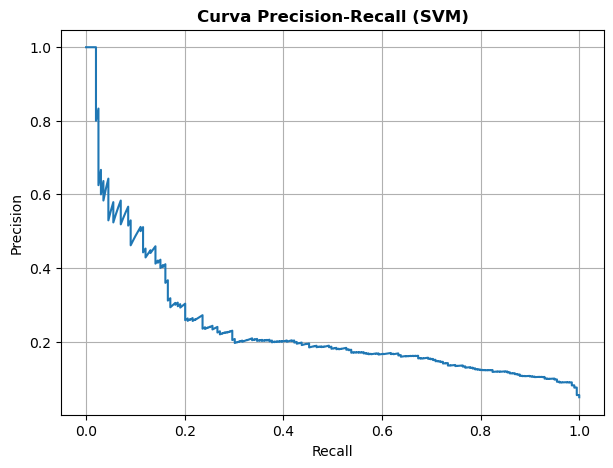

In [36]:
# Generamos una probabilidad de padecer ictus para cada paciente
y_prob = cross_val_predict(
    grid_SVM.best_estimator_,
    X_train,
    y_train,
    cv=validacion_cruzada,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculamos la curva Precision-Recall
precision, recall, thresholds = precision_recall_curve(y_train, y_prob)

# Dibujamos la curva Precision-Recall
plt.figure(figsize=(7,5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall (SVM)", fontweight = "bold")
plt.grid(True)

plt.show()

> En la gráfica de la **curva Precision-Recall (SVM)** hemos representado los verdaderos positivos que detecta el modelo SVM (Recall) frente a las predicciones positivas correctas (Precision). Podemos ver que la curva comienza con una precisión de 1, pero conforme el Recall aumenta, ésta disminuye. Esto muestra que el modelo prácticamente no se equivoca, pero se le escapan la mayoría de los casos. Conforme avanza la curva va detectando más casos, pero se generan también más falsos positivos hasta llegar al final de la gráfica, donde este efecto se hace mayor (más casos detectados y más falsos positivos). Esto que observamos es propio de datasets con un gran **desbalance de clases**.

In [37]:
# Elección del umbral de decisión
f2_scores = []   # Priorizamos Recall (penalizamos la pérdida de casos de ictus)

for t in thresholds:
    pred = (y_prob >= t).astype(int)
    f2_scores.append(fbeta_score(y_train, pred, beta=2))

best_index = np.argmax(f2_scores)
best_threshold = thresholds[best_index]

print(f"Mejor umbral: {best_threshold:.3f}")
print(f"F2-Score: {f2_scores[best_index]:.3f}")

Mejor umbral: 0.116
F2-Score: 0.412


> Decidimos calcular el **F2-Score** porque prioriza el Recall y esto hace que no aparezcan tantos falsos negativos ya que a nivel clínico es más grave eso que un falso positivo. De este modo se detectan más casos de ictus, aunque también lo hagan los falsos positivos.
>
> El valor del **umbral** que se calcula como el óptimo es **0.116** lo que indica que si hubieramos mantenido el **umbral predeterminado en 0.5** habría provocado la aparición de muchos falsos negativos.
>
> Por otra parte, el valor de **F2-Score** es de **0.412**, que es el punto donde se alcanza el equilibrio entre Precision y Recall. Esto muestra que para que el modelo pueda reducir los falsos negativos, deberán de aumentar los falsos positivos.

## 10. Evaluación del modelo

### Entrenamiento del modelo final

In [38]:
pipeline_SVM_final = grid_SVM.best_estimator_

pipeline_SVM_final.fit(X_train, y_train)

print("✅ Modelo entrenado")

✅ Modelo entrenado


### Probabilidades y aplicación del umbral

In [39]:
# Probabilidades del test
probas_test = pipeline_SVM_final.predict_proba(X_test)[:,1]
print("✅ Probabilidades obtenidas")

# Aplicación umbral elegido (0.116)
pred_test = (probas_test >= best_threshold).astype(int)
print("✅ Umbral aplicado")

✅ Probabilidades obtenidas
✅ Umbral aplicado


### Matriz de confusión

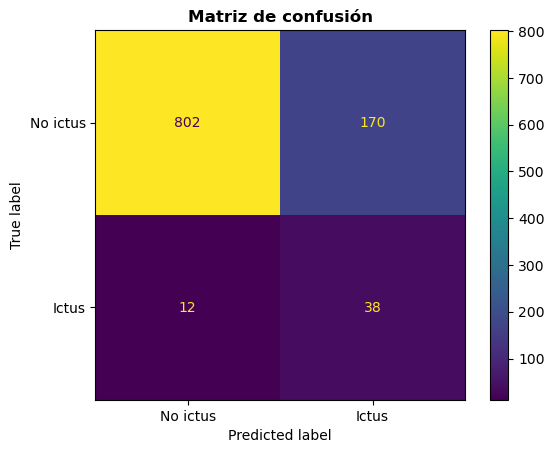

In [40]:
mc = confusion_matrix(y_test, pred_test)

matriz = ConfusionMatrixDisplay(
    confusion_matrix=mc,
    display_labels=["No ictus", "Ictus"]
)

matriz.plot()

plt.title("Matriz de confusión", fontweight = "bold")
plt.show()

> Observando la matriz podemos ver que se han detectado **38** casos como **ictus** y **802** como **sanos**. Del mismo modo, ha habido **12 falsos negativos y 170 falsos positivos**. Estos datos concuerdan con lo esperado anteriormente cuando establecimos el umbral de decisión.

### Cálculo de las métricas

In [41]:
recall = recall_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
f1 = f1_score(y_test, pred_test)
f2 = fbeta_score(y_test, pred_test, beta=2)

roc_auc = roc_auc_score(y_test, probas_test)
pr_auc = average_precision_score(y_test, probas_test)

# --- TABLA RESUMEN ---
tabla_test = pd.DataFrame({
    "Recall":[recall],
    "Precision":[precision],
    "F1-Score":[f1],
    "F2-Score":[f2],
    "ROC-AUC":[roc_auc],
    "PR-AUC":[pr_auc]
}).round(3)

tabla_test

,Recall,Precision,F1-Score,F2-Score,ROC-AUC,PR-AUC
0,0.76,0.183,0.295,0.466,0.825,0.209


> Observando la **tabla de métricas** podemos ver que el **Recall** es de 0.76, por lo que se están detectando el **76% de los ictus reales**. Respecto al **Precision** el valor es de 0.18, por lo que sólo el **18%** de los pacientes padecen **ictus de verdad**, lo que supone muchos falsos positivos, pero es algo que esperábamos. Debido a los valores de Precision y Recall, el **F1-Score** es bajo. EL **F2-Score** es más elevado ya que prioriza el Recall. El valor de **ROC-AUC** es de 0.83, un valor bueno ya que distingue bastante bien entre pacientes sanos y con ictus. Por último, el valor de **PR-AUC** también es bajo debido al gran desbalanceo de clases.

### Classification report

In [42]:
print(classification_report(y_test, pred_test))

              precision    recall  f1-score   support

           0       0.99      0.83      0.90       972
           1       0.18      0.76      0.29        50

    accuracy                           0.82      1022
   macro avg       0.58      0.79      0.60      1022
weighted avg       0.95      0.82      0.87      1022



> En este **classification report** podemos ver desglosadas las métricas según la clase **no ictus (0) e ictus (1)**. Vemos que en la **clase no ictus** el rendimiento general es muy bueno, lo que indica que el modelo detecta muy bien cuando un paciente no padece ictus. En cambio, la **clase ictus** tiene un rendimiento mucho más bajo debido a que se detectan muchos falsos positivos a causa del desbalance de las clases.
>
> Esto también se ve reflejado en el **accuracy**. Aunque el valor parezca bueno (0.82), no es un valor real ya que un modelo que predijera siempre no ictus daría un accuracy del 95%. Es por eso por lo que no hemos tenido en cuenta el accuracy a lo largo de todo el proyecto y sí otras métricas como **Recall, PR-AUC y F2-score**.
>
> El **macro avg** calcula la media dando el mismo peso a ambas clases, cosa que muestra el rendimiento global cuando se produce **desbalanceo de clases**.
>
> El **weighted avg** pondera cada clase según su número de ejemplos. De nuevo, a causa del **desbalanceo de clases**, el rendimiento sale elevado al tener más peso los pacientes sanos.

### Curva ROC

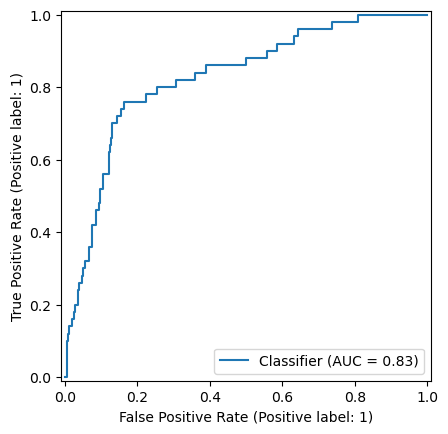

In [43]:
RocCurveDisplay.from_predictions(y_test, probas_test)

> La **curva ROC** muestra la evolución de la capacidad de clasificación del modelo conforme varía el umbral de decisión. Si dibujásemos una **diagonal** en la gráfica, veríamos que la curva se queda en la parte superior izquierda, lo que indica que consigue un **Recall elevado (0.83)** con pocos falsos positivos. Esto se traduce en que el modelo tiene una buena **capacidad de discriminación**. Aun así, no debemos confiarnos ya que hay que tener en cuenta siempre el **desbalanceo de clases**.

### Curva Precision-Recall

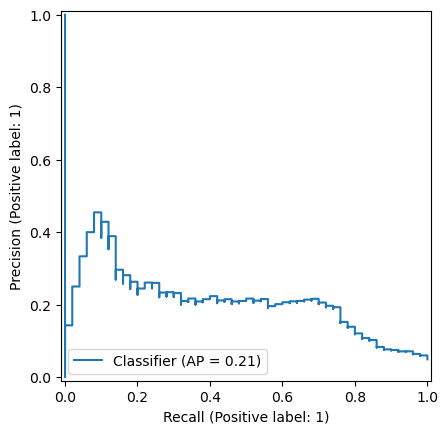

In [44]:
PrecisionRecallDisplay.from_predictions(y_test, probas_test)

> La **curva Precision-Recall** se encarga de evaluar el rendimiento sobre la clase positiva, es decir, muestra el equilibrio entre detectar la mayor cantidad de casos con ictus, pero evitando generar muchos falsos positivos. El valor de **AP (0.21)** indica que el modelo aprende más (x4) que un clasificador que no aprende de ningún patrón.
>
> Además, recordemos que el umbral de decisión quedó marcado en **0.116**. Ese umbral se encuentra en la zona central de la curva, mostrando que queremos detectar la mayoría de casos de ictus a cambio de que haya falsos positivos.
>
> Esta curva, a diferencia de la curva ROC, es **más fiable** ya que muestra mejor la capacidad que tiene el modelo de identificar los casos de ictus. Es por eso por lo que la métrica a la que más importancia le hemos dado siempre ha sido **PR-AUC**.

### Comparación con Dummy

In [51]:
# Creación Dummy
dummy = Pipeline([
    ("preprocesamiento", preprocessor_con_escalado),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

dummy.fit(X_train, y_train)

dummy_prob = dummy.predict_proba(X_test)[:,1]
dummy_pred = dummy.predict(X_test)

# Cálculo métricas
roc_auc_dummy = roc_auc_score(y_test, dummy_prob)
pr_auc_dummy = average_precision_score(y_test, dummy_prob)

print("MÉTRICAS DUMMY:\n")
print(f"ROC-AUC → {roc_auc_dummy:.3f}")
print(f"PR-AUC → {pr_auc_dummy:.3f}")

print("\nMÉTRICAS SVM:\n")
print(f"ROC-AUC → {roc_auc:.3f}")
print(f"PR-AUC → {pr_auc:.3f}")

MÉTRICAS DUMMY:

ROC-AUC → 0.500
PR-AUC → 0.049

MÉTRICAS SVM:

ROC-AUC → 0.825
PR-AUC → 0.209


> Por último, hemos usado `DummyClassifier` para ver el **rendimiento mínimo** del modelo entrenado. En este caso podemos observar que las métricas de SVM mejoran considerablamente el modelo Dummy. Si nos fijamos, el valor de **PR-AUC de Dummy** coincide con la proporción de pacientes de la clase ictus del dataset, lo que muestra que no presenta **ninguna capacidad predictiva real**. En cambio, con **SVM** el modelo mejora cuatro veces, por lo que su capacidad predictiva no es aleatoria y se ha conseguido el objetivo del proyecto.

## 11. Interpretación del modelo

### Importancia de variables

In [121]:
resultado = permutation_importance(
    pipeline_SVM_final,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importancia_variables = pd.DataFrame({"Variable": X_test.columns, "Importancia": resultado.importances_mean})
importancia_variables = importancia_variables.sort_values("Importancia", ascending=False)

importancia_variables.head(15).round(4)

,Variable,Importancia
1,age,0.0539
17,age_x_glucose,0.0507
18,is_elderly,0.0361
7,avg_glucose_level,0.0166
13,age_group,0.0161
8,bmi,0.0127
5,work_type,0.0076
19,is_child,0.0075
3,heart_disease,0.0070
0,gender,0.0044


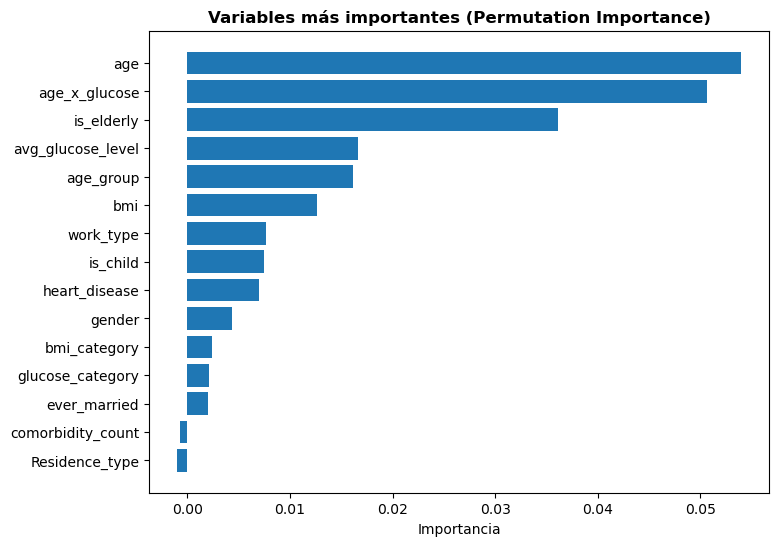

In [55]:
### --- REPRESENTACIÓN GRÁFICA ---
plt.figure(figsize=(8,6))

plt.barh(importancia_variables["Variable"][:15][::-1], importancia_variables["Importancia"][:15][::-1])

plt.xlabel("Importancia")
plt.title("Variables más importantes (Permutation Importance)", fontweight = "bold")
plt.show()

> En primer lugar, debemos de saber que `permutation_importance` mide cuánto empeora **PR-AUC**, en nuestro caso, cuando se desordena una variable. Por lo tanto, como podemos observar tanto en la tabla como en la gráfica, la variable más importante es la **edad** con un valor de **0.054**. Esto indica que, si alterásemos esta variable, el rendimiento del modelo disminuiría considerablemente, lo que coincide con todo lo analizado anteriormente.
>
> La siguiente variable con mayor importancia es **age_x_glucose**, una de las variables que hemos creado al enriquecer el dataset, con un valor de **0.051**. Este valor demuestra la relevancia de la relación entre la variable edad y la variable nivel de glucosa, de tal modo que un nivel elevado de glucosa puede afectar a personas de mayor edad.
>
> Por otra parte, la tercera variable con más importancia es **is_elderly** con un valor de **0.036**, lo que viene a confirmar de nuevo que la edad, y en este caso el envejecimiento, es el factor más influyente en la predicción de ictus.

### ¿El modelo está sobreajustado?

In [68]:
print("COMPARACIÓN TRAIN vs. TEST")
print(f"PR-AUC en validación cruzada: {grid_SVM.best_score_:.3f}")
print(f"PR-AUC en test: {pr_auc:.3f}")

diferencia = grid_SVM.best_score_ - pr_auc
print(f"Diferencia: {diferencia:.3f}")

print("\nInterpretación:")
if diferencia < 0.05:
    print("→ No se observan indicios claros de sobreajuste.")
elif diferencia < 0.10:
    print("→ Existe un ligero sobreajuste.")
else:
    print("→ El modelo presenta un sobreajuste importante.")

COMPARACIÓN TRAIN vs. TEST
PR-AUC en validación cruzada: 0.255
PR-AUC en test: 0.209
Diferencia: 0.046

Interpretación:
→ No se observan indicios claros de sobreajuste.


> Para comprobar si el modelo está sobreajustado debemos de comparar el rendimiento obtenido durante la validación cruzada y el test y obtener la diferencia. La **diferencia de PR-AUC** es de **0.046**, un valor pequeño (< 0.05) que demuestra que **no existen indicios evidentes de sobreajuste**. Esto se puede traducir en que el modelo mantiene su comportamiento y capacidad predictiva con datos nuevos.

### Estabilidad entre folds

In [65]:
SVM = tabla_modelos[tabla_modelos["Modelo"]=="SVM"]

print("ESTABILIDAD ENTRE FOLDS (SVM):")
print(f"Recall std: {SVM['Recall std'].values[0]:.3f}")
print(f"Precision std: {SVM['Precision std'].values[0]:.3f}")
print(f"F1-Score std: {SVM['F1-Score std'].values[0]:.3f}")
print(f"ROC-AUC std: {SVM['ROC-AUC std'].values[0]:.3f}")
print(f"PR-AUC std: {SVM['PR-AUC std'].values[0]:.3f}")

ESTABILIDAD ENTRE FOLDS (SVM):
Recall std: 0.029
Precision std: 0.011
F1-Score std: 0.016
ROC-AUC std: 0.019
PR-AUC std: 0.015


> Para poder ver la estabilidad entre folds es necesario calcular la **desviación estándar** de cada métrica, de tal modo que podemos ver si varían o no. En nuestro caso observamos que todas las métricas muestran una **estabilidad elevada** ya que sus valores están en torno a **0.02**. Cuando la desviación estándar es próxima a 0 indica que el modelo mantiene el comportamiento, por lo que es **robusto** y **estable**.
>
> Cabe destacar el valor de **PR-AUC** que tiene una de las desviaciones estándar más bajas, demostrando una vez más que el rendimiento es consistente y no depende de la partición en gran medida.

### Análisis de errores

In [59]:
errores = X_test.copy()

errores["Real"] = y_test.values
errores["Pred"] = pred_test

falsos_negativos = errores[
    (errores["Real"]==1) &
    (errores["Pred"]==0)
]

falsos_negativos

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,...,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,Real,Pred
133,Female,38.0,0,0,Yes,Private,Rural,101.45,NaN,formerly smoked,...,0,0.0,0.0,38.55,0,0,0,0,1,0
94,Male,45.0,0,0,Yes,Private,Rural,64.14,29.4,never smoked,...,0,0.0,0.0,28.86,0,0,0,0,1,0
182,Female,32.0,0,0,Yes,Private,Rural,76.13,29.9,smokes,...,0,0.0,0.0,24.36,0,0,0,0,1,0
195,Male,59.0,0,0,Yes,Private,Urban,200.62,35.8,formerly smoked,...,0,0.0,0.0,118.37,0,0,1,1,1,0
88,Male,47.0,0,0,Yes,Private,Urban,86.94,41.1,formerly smoked,...,0,0.0,0.0,40.86,0,0,0,1,1,0
80,Male,59.0,0,0,Yes,Private,Rural,96.16,44.1,Unknown,...,0,0.0,0.0,56.73,0,0,0,1,1,0
210,Female,39.0,0,0,Yes,Private,Urban,83.24,26.3,never smoked,...,0,0.0,0.0,32.46,0,0,0,0,1,0
245,Female,14.0,0,0,No,children,Rural,57.93,30.9,Unknown,...,0,0.0,0.0,8.11,0,1,0,1,1,0
31,Male,42.0,0,0,Yes,Private,Rural,83.41,25.4,Unknown,...,0,0.0,0.0,35.03,0,0,0,0,1,0
98,Male,57.0,1,0,Yes,Govt_job,Urban,78.92,27.7,formerly smoked,...,1,57.0,0.0,44.98,0,0,0,0,1,0


In [64]:
falsos_negativos.describe().round(3)

,age,hypertension,heart_disease,avg_glucose_level,bmi,bmi_missing,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,Real,Pred
count,12.000,12.000,12.0,12.000,11.000,12.000,12.000,12.000,12.0,12.000,12.0,12.000,12.000,12.000,12.0,12.0
mean,44.083,0.083,0.0,93.277,32.018,0.083,0.083,4.750,0.0,43.347,0.0,0.083,0.083,0.417,1.0,0.0
std,13.345,0.289,0.0,36.250,5.969,0.289,0.289,16.454,0.0,26.924,0.0,0.289,0.289,0.515,0.0,0.0
min,14.000,0.000,0.0,57.930,25.400,0.000,0.000,0.000,0.0,8.110,0.0,0.000,0.000,0.000,1.0,0.0
25%,38.750,0.000,0.0,78.222,28.550,0.000,0.000,0.000,0.0,31.560,0.0,0.000,0.000,0.000,1.0,0.0
50%,43.500,0.000,0.0,85.175,29.900,0.000,0.000,0.000,0.0,38.340,0.0,0.000,0.000,0.000,1.0,0.0
75%,57.250,0.000,0.0,96.560,33.900,0.000,0.000,0.000,0.0,47.165,0.0,0.000,0.000,1.000,1.0,0.0
max,59.000,1.000,0.0,200.620,44.100,1.000,1.000,57.000,0.0,118.370,0.0,1.000,1.000,1.000,1.0,0.0


> A partir de la matriz de confusión que obtuvimos anteriormente vimos que el modelo clasificaba 12 casos como falsos negativos y 170 casos como falsos positivos. Vamos a centrarnos en los **falsos negativos** ya que a nivel clínico tienen mayor importancia. Para ello vamos a ver si tienen **características comunes** o **factores de riesgo marcados**.
>
> Observando ambas tablas podemos ver que en la mayoría de casos esto no ocurre, es decir, la mayoría de los casos no presentan una edad elevada, hipertensión, enfermedad cardíaca o comorbilidades. Esto nos demuestra que el modelo tiene la capacidad de detectar correctamente los factores de riesgo de mayor importancia, pero presenta dificultades con pacientes que, *a priori*, pueden tener características propias de gente sana.
>
> Por lo tanto, parece ser que los casos de falsos negativos se corresponden con pacientes que presentan un **riesgo menos evidente**, dificultando de este modo su correcta predicción.

---

## 12. WebApp con streamlit

### Instalación de streamlit

In [69]:
!pip install streamlit

In [70]:
!streamlit hello


      👋 Welcome to Streamlit!

      If you'd like to receive helpful onboarding emails, news, offers, promotions,
      and the occasional swag, please enter your email address below. Otherwise,
      leave this field blank.

      Email:  ^C
2026-08-05 18:42:49.111 


In [73]:
!pip install joblib

### Guardar el modelo desde el notebook

In [109]:
import joblib

ruta = "/Users/Cristina/Documents/Curso Inteligencia Artifical EOI/Proyecto IA/app_ictus/modelo.joblib"

joblib.dump({
        "modelo": pipeline_SVM_final,
        "umbral": best_threshold
    }, ruta)

print("✅ Modelo guardado correctamente")

✅ Modelo guardado correctamente


In [119]:
# Comprobación que se puede cargar el modelo correctamente
modelo = joblib.load("modelo.joblib")

pipeline = modelo["modelo"]
umbral = modelo["umbral"]

print("Pipeline:", type(pipeline))
print("Umbral:", umbral)

Pipeline: <class 'sklearn.pipeline.Pipeline'>
Umbral: 0.11622759841539394


### ⚠️ El resto de pasos para la elaboración de la WebApp se ha realizado fuera de este notebook

---